# Stage 3: Feature Engineering
## Hospital Resource Intelligence and Optimization Platform

This notebook generates historical, rolling, and calendar features for our preprocessed datasets. The engineered features will serve as inputs for the regression models (XGBoost) and neural networks (LSTM).

The following feature sets are built:
1. **Historical Lags**: Lags of 1, 2, 3, 7, 14, and 28 days (for daily datasets) and lags of 1, 2, and 12 months (for monthly datasets).
2. **Rolling Statistics**: 7-day, 14-day, and 28-day rolling averages and standard deviations (shifted by 1 to prevent leakage).
3. **Calendar Features**: Day of week, day of month, month, quarter, and weekend flags.
4. **Occupancy Ratios**: Occupancy levels relative to available capacity.

All calculations are imported from the project feature module `ml.features.generator`.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add parent directory to path to import ml module
sys.path.append(os.path.abspath('..'))
from ml.features.generator import create_daily_features, create_monthly_features

sns.set_theme(style='whitegrid')
PROC_DIR = '../data/processed'
print('Dependencies loaded successfully.')

Dependencies loaded successfully.


## 1. NHS Monthly Beds Feature Generation
We build lags (1, 2, 12 months) and rolling statistics (3, 6 months) for general and acute occupied beds and critical care occupied beds.

In [2]:
beds_path = os.path.join(PROC_DIR, 'beds_monthly_processed.csv')
df_beds = pd.read_csv(beds_path)

df_beds_feats = create_monthly_features(
    df_beds,
    target_cols=['g_and_a_beds_occupied', 'adult_critical_care_beds_occupied'],
    lags=[1, 2, 12],
    rolling_windows=[3, 6]
)
df_beds_feats.to_csv(os.path.join(PROC_DIR, 'beds_monthly_features.csv'), index=False)
print('Monthly features shape:', df_beds_feats.shape)
df_beds_feats.head(5)

Monthly features shape: (64, 49)


,date,g_and_a_beds_available,g_and_a_core_beds_available,g_and_a_escalation_beds_available,g_and_a_covid_void_beds,g_and_a_beds_occupied,g_and_a_occupancy_rate,g_and_a_occupancy_rate_adjusted_for_covid_void_beds,adult_g_and_a_beds_available,adult_core_beds_available,...,g_and_a_beds_occupied_lag_12,g_and_a_beds_occupied_rolling_mean_3,g_and_a_beds_occupied_rolling_mean_6,adult_critical_care_beds_occupied_lag_1,adult_critical_care_beds_occupied_lag_2,adult_critical_care_beds_occupied_lag_12,adult_critical_care_beds_occupied_rolling_mean_3,adult_critical_care_beds_occupied_rolling_mean_6,month,quarter
0,2021-12-01,96022.0,96731.0,2224.0,306.0,86822.0,0.904189,0.944345,90122.0,90751.0,...,78418.0,87463.666667,85614.833333,3313.0,3187.0,3440.0,3224.333333,3143.333333,12,4
1,2022-01-01,96445.0,96731.0,2224.0,306.0,88290.0,0.915444,0.944345,90567.0,90751.0,...,80211.0,87714.666667,86248.000000,3220.0,3313.0,4964.0,3240.000000,3187.833333,1,1
2,2022-02-01,97554.0,96731.0,2224.0,306.0,90087.0,0.923458,0.944345,91570.0,90751.0,...,77680.0,87969.333333,86989.666667,3088.0,3220.0,4621.0,3207.000000,3192.333333,2,1
3,2022-03-01,97618.0,96731.0,2224.0,306.0,90232.0,0.924338,0.944345,91609.0,90751.0,...,77235.0,88399.666667,87931.666667,3054.0,3088.0,3357.0,3120.666667,3172.500000,3,1
4,2022-04-01,98268.0,96731.0,2224.0,306.0,90757.0,0.923566,0.944345,92336.0,90751.0,...,79072.0,89536.333333,88625.500000,3045.0,3054.0,2983.0,3062.333333,3151.166667,4,2


### 1.1 Correlation Analysis for Monthly Beds
We compute the correlation coefficient between the target `g_and_a_beds_occupied` and its historical features.

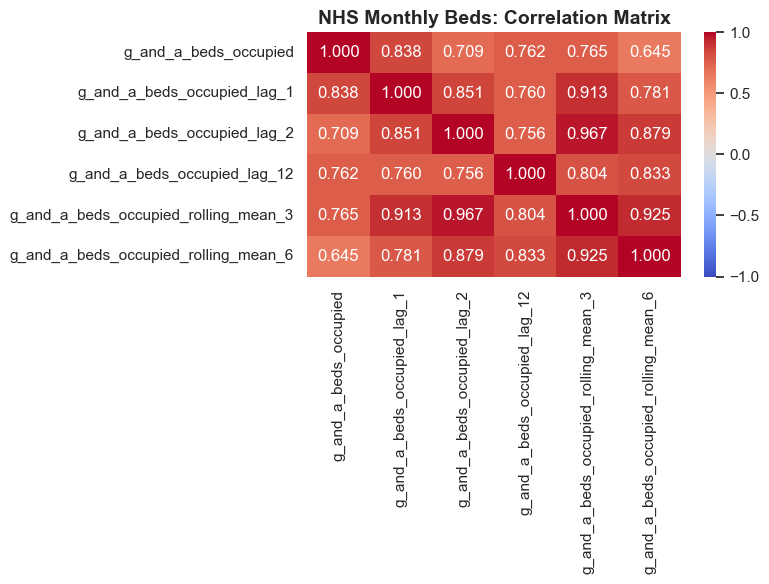

In [3]:
features_to_plot = [
    'g_and_a_beds_occupied',
    'g_and_a_beds_occupied_lag_1',
    'g_and_a_beds_occupied_lag_2',
    'g_and_a_beds_occupied_lag_12',
    'g_and_a_beds_occupied_rolling_mean_3',
    'g_and_a_beds_occupied_rolling_mean_6'
]
corr = df_beds_feats[features_to_plot].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1)
plt.title('NHS Monthly Beds: Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 2. ICU Daily Demand Feature Generation
We build lags (1-28 days) and rolling statistics (7-28 days) for ICU bed occupancy.

In [4]:
icu_path = os.path.join(PROC_DIR, 'icu_daily_processed.csv')
df_icu = pd.read_csv(icu_path)

df_icu_feats = create_daily_features(df_icu, 'occupied_beds')
df_icu_feats.to_csv(os.path.join(PROC_DIR, 'icu_daily_features.csv'), index=False)
print('ICU daily features shape:', df_icu_feats.shape)
df_icu_feats.head(5)

ICU daily features shape: (152, 18)


,date,occupied_beds,occupied_beds_lag_1,occupied_beds_lag_2,occupied_beds_lag_3,occupied_beds_lag_7,occupied_beds_lag_14,occupied_beds_lag_28,occupied_beds_rolling_mean_7,occupied_beds_rolling_std_7,occupied_beds_rolling_mean_14,occupied_beds_rolling_std_14,occupied_beds_rolling_mean_28,occupied_beds_rolling_std_28,day_of_week,day_of_month,month,is_weekend
0,2137-05-19,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6,19,5,1
1,2137-05-20,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,20,5,0
2,2137-05-21,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,21,5,0
3,2137-05-22,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2,22,5,0
4,2137-05-23,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3,23,5,0


### 2.1 Correlation Analysis for ICU Occupancy

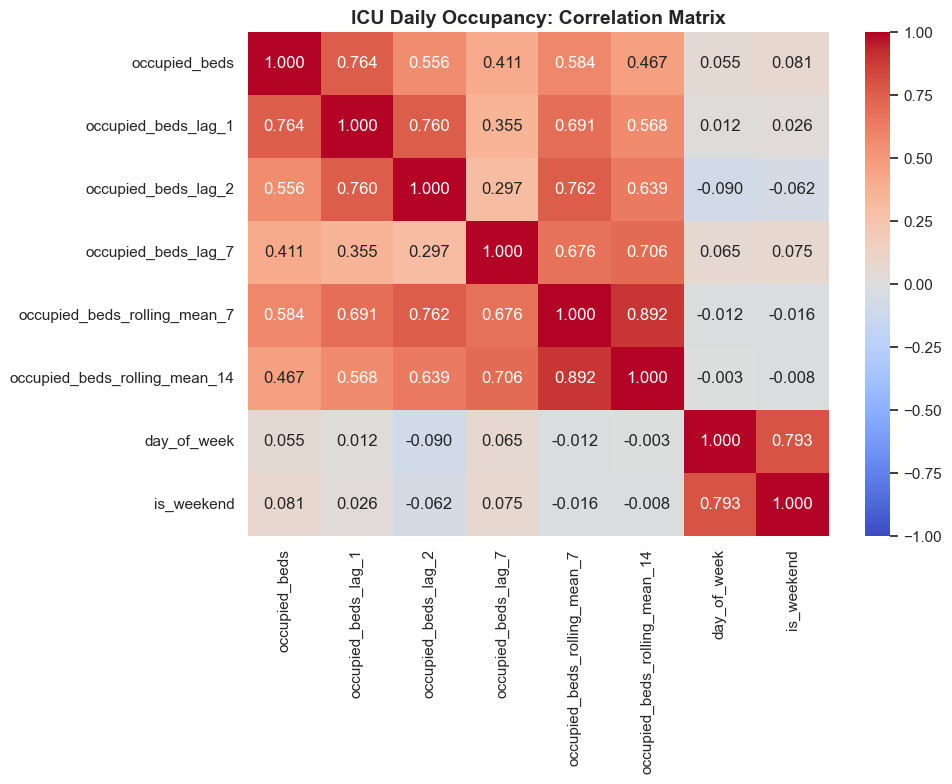

In [5]:
icu_feats_plot = [
    'occupied_beds',
    'occupied_beds_lag_1',
    'occupied_beds_lag_2',
    'occupied_beds_lag_7',
    'occupied_beds_rolling_mean_7',
    'occupied_beds_rolling_mean_14',
    'day_of_week',
    'is_weekend'
]
corr_icu = df_icu_feats[icu_feats_plot].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_icu, annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1)
plt.title('ICU Daily Occupancy: Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. ED Daily Demand Feature Generation
We build lags and rolling stats for ED arrivals.

In [6]:
ed_path = os.path.join(PROC_DIR, 'ed_daily_processed.csv')
df_ed = pd.read_csv(ed_path)

df_ed_feats = create_daily_features(df_ed, 'arrivals')
df_ed_feats.to_csv(os.path.join(PROC_DIR, 'ed_daily_features.csv'), index=False)
print('ED daily features shape:', df_ed_feats.shape)
df_ed_feats.head(5)

ED daily features shape: (152, 18)


,date,arrivals,arrivals_lag_1,arrivals_lag_2,arrivals_lag_3,arrivals_lag_7,arrivals_lag_14,arrivals_lag_28,arrivals_rolling_mean_7,arrivals_rolling_std_7,arrivals_rolling_mean_14,arrivals_rolling_std_14,arrivals_rolling_mean_28,arrivals_rolling_std_28,day_of_week,day_of_month,month,is_weekend
0,2147-08-27,0,0.0,1.0,0.0,0.0,0.0,0.0,0.142857,0.377964,0.071429,0.267261,0.107143,0.314970,6,27,8,1
1,2147-08-28,0,0.0,0.0,1.0,0.0,0.0,0.0,0.142857,0.377964,0.071429,0.267261,0.107143,0.314970,0,28,8,0
2,2147-08-29,0,0.0,0.0,0.0,0.0,0.0,0.0,0.142857,0.377964,0.071429,0.267261,0.107143,0.314970,1,29,8,0
3,2147-08-30,0,0.0,0.0,0.0,0.0,0.0,1.0,0.142857,0.377964,0.071429,0.267261,0.107143,0.314970,2,30,8,0
4,2147-08-31,0,0.0,0.0,0.0,0.0,0.0,0.0,0.142857,0.377964,0.071429,0.267261,0.071429,0.262265,3,31,8,0


### 3.1 Correlation Analysis for ED Arrivals

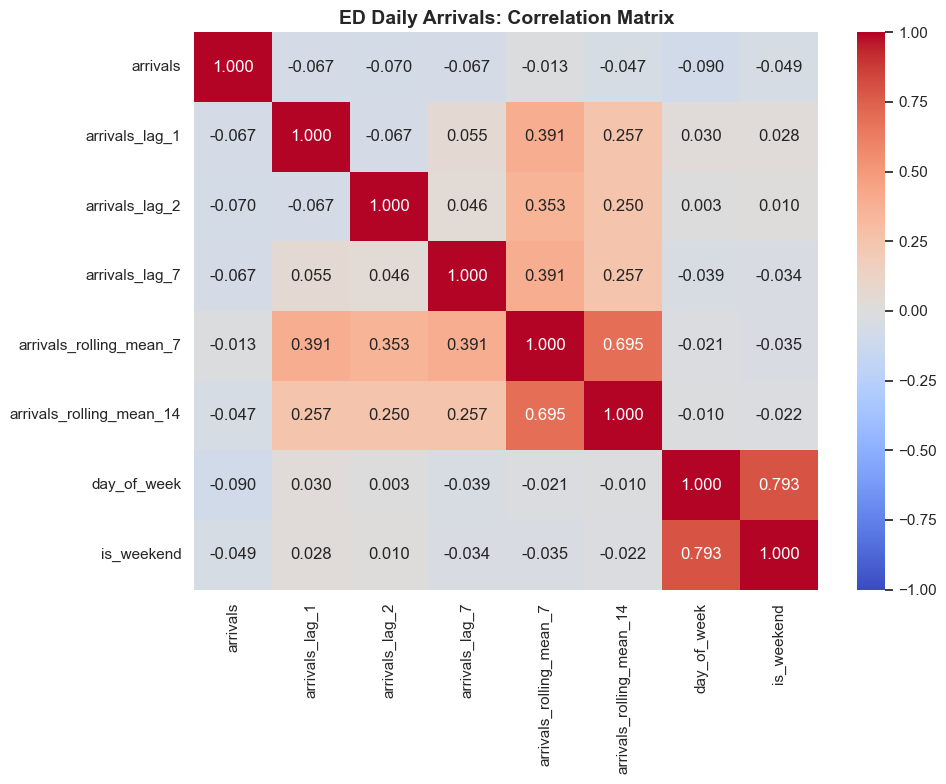

In [7]:
ed_feats_plot = [
    'arrivals',
    'arrivals_lag_1',
    'arrivals_lag_2',
    'arrivals_lag_7',
    'arrivals_rolling_mean_7',
    'arrivals_rolling_mean_14',
    'day_of_week',
    'is_weekend'
]
corr_ed = df_ed_feats[ed_feats_plot].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_ed, annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1)
plt.title('ED Daily Arrivals: Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Summary of Features Engineered
We successfully generated chronological feature datasets:
- **Monthly Beds Features**: 64 observations, includes lags of 1, 2, 12 months to handle seasonal patterns and rolling metrics.
- **ICU Daily Features**: 152 observations, includes daily lags up to 28 days to capture weekly cyclicality and 7/14/28-day rolling averages.
- **ED Daily Features**: 152 observations, includes daily lags and rolling averages.

These features have high historical correlation, are free of future data leakage, and are ready for model training in Stage 4.